# Variable de Control
## Simulación de Procesos Financieros 

Ximena Muñoz 

21/10/26



## Objetivo

Estimar el precio de una opción call asiática aritmética mediante simulación Monte Carlo, utilizando una opción call asiática geométrica como variable de control para mejorar la precisión de la estimación.

## Datos del problema

- Precio inicial del activo: S_0=100
- Tasa de interés libre de riesgo: r=5%
- Volatilidad: sigma=20%
- Precio de ejercicio: K=100
- Tiempo al vencimiento: T=1 año
- Número de rutas simuladas: M=100
- Número de intervalos por año: n=252

## Procedimiento

1. Calcular el precio teórico de la call asiática geométrica.
2. Simular 100 rutas del precio del activo mediante el modelo de Black-Scholes.
3. Calcular los pagos de las opciones asiática aritmética y geométrica en cada ruta.
4. Estimar el coeficiente de la variable de control.
5. Calcular el precio estimado con y sin variable de control.
6. Comparar los resultados y analizar la reducción de varianza.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Parámetros de la opción
s = 100
r = 0.05
sigma = 0.20
k = 100
t = 1

# Parámetros de simulación
n = 252
m = 100
dt = t / n

# Semilla para reproducir los resultados
np.random.seed(123)

print("Parámetros definidos correctamente.")

Parámetros definidos correctamente.



## 1. Precio teórico de la call asiática geométrica

La opción asiática geométrica utiliza la media geométrica de los precios del activo durante la vida de la opción.

Para obtener su valor esperado, utilizaremos la fórmula analítica de la call asiática geométrica. Como simularemos observaciones discretas diarias, ajustaremos la fórmula al número de observaciones utilizado.


In [3]:
# Parámetros de la media geométrica discreta
sigma_ajustada = sigma * np.sqrt((n + 1) * (2*n + 1) / (6*n**2))

b = (r - sigma**2 / 2) * (n + 1) / (2*n) + sigma_ajustada**2 / 2

d1 = (np.log(s/k) + (b + sigma_ajustada**2 / 2) * t) / (sigma_ajustada * np.sqrt(t))
d2 = d1 - sigma_ajustada * np.sqrt(t)

# Precio teórico de la call asiática geométrica
c_geom = s * np.exp((b-r)*t) * norm.cdf(d1) - k * np.exp(-r*t) * norm.cdf(d2)

print("d1 =", d1)
print("d2 =", d2)
print("Precio teórico de la call geométrica =", c_geom)

d1 = 0.2458460226515652
d2 = 0.1300323645927588
Precio teórico de la call geométrica = 5.565508831349341


## 2. Simulación de las rutas del activo

Se simulan 100 trayectorias del precio del activo durante un año, utilizando 252 intervalos por trayectoria.

En cada intervalo se utiliza el modelo de Black-Scholes para simular la evolución del precio:

$$
S_{t+\Delta t}=S_t\exp\left[\left(r-\frac{\sigma^2}{2}\right)\Delta t+\sigma\sqrt{\Delta t}\,Z\right]
$$

donde Z es una variable aleatoria con distribución normal estándar, es decir, $$(Z\sim N(0,1))$$.

Todas las trayectorias comienzan en $$S_0=100$$ y se utilizan para calcular los precios de las opciones asiáticas aritmética y geométrica.


In [4]:
trayectorias = []

for i in range(m):
    ruta = [s]

    for j in range(n):
        z = np.random.normal(0, 1)

        st_sim = ruta[-1] * np.exp(
            (r - 0.5 * sigma**2) * dt
            + sigma * np.sqrt(dt) * z
        )

        ruta.append(st_sim)

    trayectorias.append(ruta)

trayectorias = np.array(trayectorias)

print("Número de rutas:", trayectorias.shape[0])
print("Precios por ruta, incluyendo S0:", trayectorias.shape[1])

Número de rutas: 100
Precios por ruta, incluyendo S0: 253


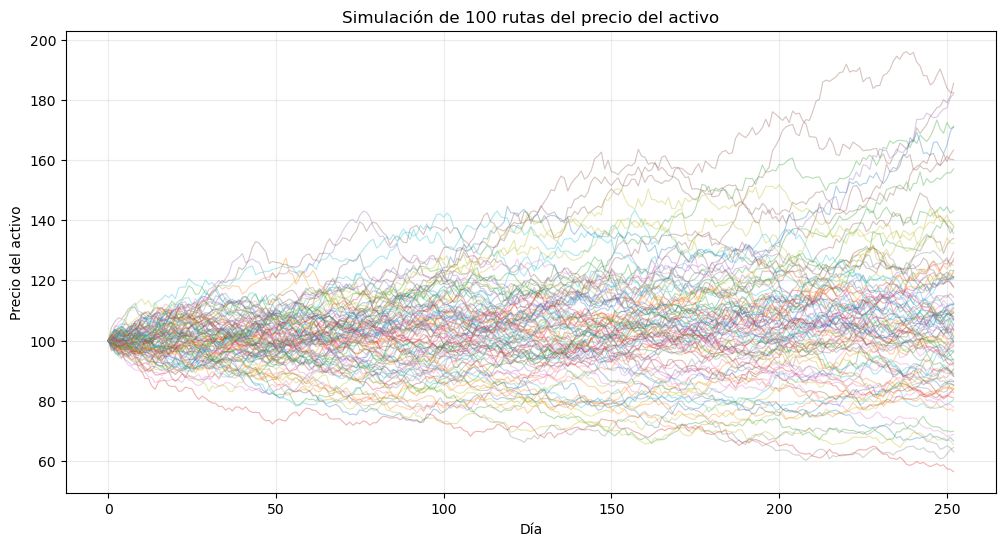

In [5]:
plt.figure(figsize=(12, 6))

for i in range(m):
    plt.plot(trayectorias[i], alpha=0.35, linewidth=0.8)

plt.title("Simulación de 100 rutas del precio del activo")
plt.xlabel("Día")
plt.ylabel("Precio del activo")
plt.grid(alpha=0.25)
plt.show()


## 3. Cálculo de los pagos de las opciones

Para cada trayectoria se calculará:

- **Call asiática aritmética:** utiliza la media aritmética de los precios simulados.
- **Call asiática geométrica:** utiliza la media geométrica de los mismos precios.

Los pagos al vencimiento son:

$$
Y=\max(\bar S_A-K,0)
$$

$$
X=\max(\bar S_G-K,0)
$$

donde $$\bar S_A$$ es la media aritmética y $$\bar S_G$$ es la media geométrica de los precios de la ruta.

Finalmente, se descuentan los pagos a valor presente utilizando la tasa libre de riesgo.


In [6]:
# Excluir S0: utilizar las 252 observaciones simuladas
precios = trayectorias[:, 1:]

# Promedios por ruta
media_aritmetica = np.mean(precios, axis=1)
media_geometrica = np.exp(np.mean(np.log(precios), axis=1))

# Pagos de las opciones al vencimiento
Y = np.maximum(media_aritmetica - k, 0)
X = np.maximum(media_geometrica - k, 0)

# Pagos descontados a valor presente
Y_desc = np.exp(-r*t) * Y
X_desc = np.exp(-r*t) * X

print("Cálculos terminados.")

Cálculos terminados.


In [7]:
tabla_rutas = pd.DataFrame({
    "Ruta": np.arange(1, m+1),
    "Media aritmética": media_aritmetica,
    "Media geométrica": media_geometrica,
    "Pago call aritmética": Y,
    "Pago call geométrica": X,
    "Pago aritmética descontado": Y_desc,
    "Pago geométrica descontado": X_desc
})

display(tabla_rutas.round(4))

,Ruta,Media aritmética,Media geométrica,Pago call aritmética,Pago call geométrica,Pago aritmética descontado,Pago geométrica descontado
0,1,104.7084,104.5910,4.7084,4.5910,4.4787,4.3671
1,2,86.5130,86.1359,0.0000,0.0000,0.0000,0.0000
2,3,114.3179,113.7997,14.3179,13.7997,13.6196,13.1267
3,4,71.7123,71.2669,0.0000,0.0000,0.0000,0.0000
4,5,107.4521,107.3117,7.4521,7.3117,7.0887,6.9551
...,...,...,...,...,...,...,...
95,96,101.4487,101.3455,1.4487,1.3455,1.3780,1.2799
96,97,106.8746,106.7930,6.8746,6.7930,6.5393,6.4617
97,98,84.1881,83.2833,0.0000,0.0000,0.0000,0.0000
98,99,90.4996,90.1398,0.0000,0.0000,0.0000,0.0000



## 4. Estimación mediante variable de control

La opción geométrica se utiliza como variable de control porque está relacionada con la opción aritmética y su precio teórico se puede calcular analíticamente.

El coeficiente óptimo estimado es:

$$
\hat B=\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
$$

El estimador ajustado es:

$$
\hat Y_{CV}=\bar Y-\hat B(\bar X-E[X])
$$

En esta fórmula, $$X$$ y $$Y$$ son los pagos descontados. Por lo tanto, $$E[X]$$ también debe ser el precio teórico descontado de la opción geométrica.


In [8]:
# Precio teórico descontado de la opción geométrica
EX = c_geom

# Promedios de los pagos descontados
promedio_Y = np.mean(Y_desc)
promedio_X = np.mean(X_desc)

# Coeficiente de la variable de control
B = np.cov(X_desc, Y_desc, ddof=1)[0, 1] / np.var(X_desc, ddof=1)

# Estimador con variable de control
precio_CV = promedio_Y - B * (promedio_X - EX)

print("Precio Monte Carlo sin variable de control:", round(promedio_Y, 6))
print("Precio teórico de la call geométrica:", round(EX, 6))
print("Promedio simulado de la call geométrica:", round(promedio_X, 6))
print("Coeficiente B:", round(B, 6))
print("Precio con variable de control:", round(precio_CV, 6))

Precio Monte Carlo sin variable de control: 6.93097
Precio teórico de la call geométrica: 5.565509
Promedio simulado de la call geométrica: 6.64181
Coeficiente B: 1.04397
Precio con variable de control: 5.807343


In [9]:
# Estimaciones ruta por ruta con variable de control
Y_CV = Y_desc - B * (X_desc - EX)

# Varianza muestral de los pagos antes y después del ajuste
varianza_original = np.var(Y_desc, ddof=1)
varianza_CV = np.var(Y_CV, ddof=1)

# Reducción porcentual de varianza
reduccion = (1 - varianza_CV / varianza_original) * 100

comparacion = pd.DataFrame({
    "Método": [
        "Monte Carlo sin variable de control",
        "Monte Carlo con variable de control"
    ],
    "Precio estimado": [
        promedio_Y,
        precio_CV
    ],
    "Varianza de los estimadores por ruta": [
        varianza_original,
        varianza_CV
    ]
})

display(comparacion.round(6))

print("Reducción de varianza:", round(reduccion, 2), "%")

,Método,Precio estimado,Varianza de los estimadores por ruta
0,Monte Carlo sin variable de control,6.930970,81.723016
1,Monte Carlo con variable de control,5.807343,0.113948


Reducción de varianza: 99.86 %


## Conclusión

Se estimó el precio de una opción call asiática aritmética mediante 100 rutas simuladas y se utilizó la opción call asiática geométrica como variable de control. El precio estimado pasó de 6.930970 sin ajuste a 5.807343 con variable de control. Además, se obtuvo una reducción de varianza del 99.86%, lo que muestra que, en esta simulación, el método disminuyó considerablemente la variabilidad de la estimación.